## Accessing Animal Tracking - Satellite Relay Tagging - Delayed Mode - GPS (Parquet)
This Jupyter notebook demonstrates how to access and plot animal_gps_satellite_relay_tagging_location_qc_delayed_qc data, available as a [Parquet](https://parquet.apache.org) dataset stored on S3.

🔗 More information about the dataset is available [in the AODN metadata catalogue](https://catalogue-imos.aodn.org.au/geonetwork/srv/eng/catalog.search#/metadata/70f148b1-7040-4fad-944a-456413c95472).

📌 The source of truth for this notebook is maintained on [GitHub](https://github.com/aodn/aodn_cloud_optimised/tree/main/notebooks/animal_gps_satellite_relay_tagging_location_qc_delayed_qc.ipynb).


In [1]:
dataset_name = "animal_gps_satellite_relay_tagging_location_qc_delayed_qc"

## Install/Update packages and Load common functions

In [2]:
import os, requests, importlib.util

open('setup.py', 'w').write(requests.get('https://raw.githubusercontent.com/aodn/aodn_cloud_optimised/main/notebooks/setup.py').text)

spec = importlib.util.spec_from_file_location("setup", "setup.py")
setup = importlib.util.module_from_spec(spec)
spec.loader.exec_module(setup)

setup.install_requirements()
setup.load_dataquery()

✅ Virtual environment already exists, skipping creation.


Using Python 3.12.11 environment at: /home/ecougnon/anaconda3/envs/AodnCloudOptimised
Resolved 201 packages in 66ms
Audited 201 packages in 0.06ms


✅ Local version 0.3.30 is up to date (remote: 0.3.30)


In [ ]:
from DataQuery import GetAodn

# Understanding the Dataset

## Understanding Parquet Partitioning

Parquet files can be **partitioned** by one or more columns, which means the data is physically organised into folders based on the values in those columns. This is similar to how databases use indexes to optimise query performance.

Partitioning enables **faster filtering**: when you query data using a partitioned column, only the relevant subset of files needs to be read—improving performance significantly.

For example, if a dataset is partitioned by `"site_code"`, `"timestamp"`, and `"polygon"`, filtering on `"site_code"` allows the system to skip unrelated files entirely.

In this notebook, the `GetAodn` class includes built-in methods to efficiently filter data by **time** and **latitude/longitude** using the **timestamp** and **polygon** partitions. Other partitions can be used for filtering via the `scalar_filter`.

Any filtering on columns that are **not** partitioned can be significantly slower, as all files may need to be scanned. However, the `GetAodn` class provides a `scalar_filter` method that lets you apply these filters at load time—before the data is fully read—helping reduce the size of the resulting DataFrame.

Once the dataset is loaded, further filtering using Pandas is efficient and flexible.

See further below in the notebook for examples of how to filter the data effectively.

To view the actual partition columns for this dataset, run:


In [4]:
aodn = GetAodn()
dname = f'{dataset_name}.parquet'
%time aodn_dataset = aodn.get_dataset(dname)

CPU times: user 5.26 ms, sys: 1.82 ms, total: 7.07 ms
Wall time: 6.14 ms


In [5]:
aodn_dataset.dataset.partitioning.schema

timestamp: int32
polygon: string

## List unique partition values

In [6]:
%%time
unique_partition_value = aodn_dataset.get_unique_partition_values('YOUR_PARTITION_KEY')
print(list(unique_partition_value)[0:2])  # showing a subset only

[]
CPU times: user 340 µs, sys: 86 µs, total: 426 µs
Wall time: 363 µs


## Visualise Spatial Extent of the dataset
This section plots the polygons representing the areas where data is available. It helps to identify and create a bounding box around the regions containing data.

/home/ecougnon/anaconda3/envs/AodnCloudOptimised/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


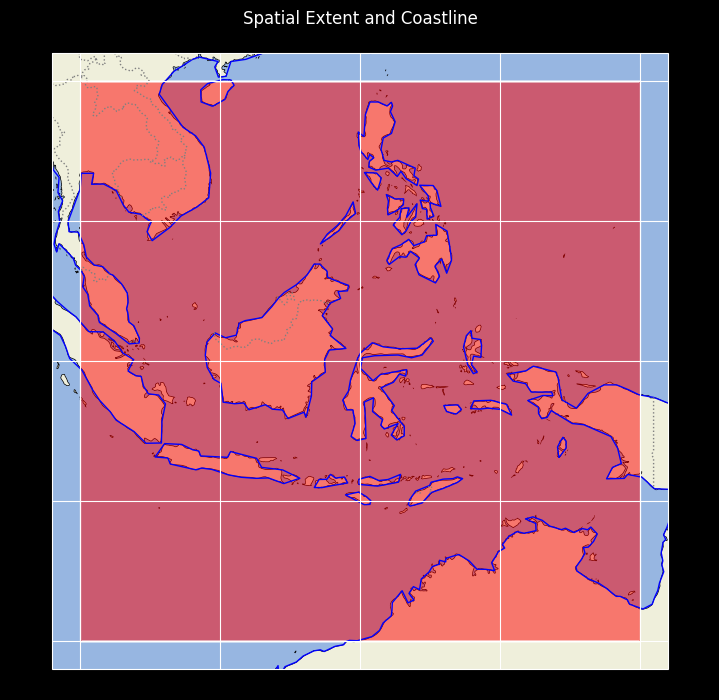

In [6]:
aodn_dataset.plot_spatial_extent()

## Get Temporal Extent of the dataset

Similary to the spatial extent, we're retrieving the minimum and maximum timestamp partition values of the dataset. This is not necessarely accurately representative of the TIME values, as the timestamp partition can be yearly/monthly... but is here to give an idea

In [7]:
%%time
aodn_dataset.get_temporal_extent()

CPU times: user 11.9 ms, sys: 3.25 ms, total: 15.1 ms
Wall time: 168 ms


(Timestamp('2025-04-24 03:31:19'), Timestamp('2025-08-17 01:53:07'))

## Read Metadata

For all Parquet datasets, we create a sidecar file named **_common_metadata** in the root of the dataset. This file contains both the dataset-level and variable-level attributes.  
The metadata can be retrieved below as a dictionary, and it will also be included in the pandas DataFrame when using the `get_data` method from the `GetAodn` class.

In [8]:
metadata = aodn_dataset.get_metadata()
metadata

2026-10-14 09:03:37,965 - aodn.GetAodn - INFO - Retrieving metadata for imos-optimised-nonproduction/animal_gps_satellite_relay_tagging_location_qc_delayed_qc.parquet


{'cid': {'type': 'string', 'comment': 'SMRU campaign name '},
 'cnt': {'type': 'int32',
  'comment': 'The number of times that this record was received'},
 'lat': {'type': 'double',
  'units': 'degrees_north',
  'comment': 'Position estimate (WGS 84 datum)',
  'long_name': 'Latitude'},
 'lon': {'type': 'double',
  'units': 'degrees_east',
  'comment': 'Position estimate (WGS 84 datum)',
  'long_name': 'Longitude'},
 'ptt': {'type': 'int32',
  'comment': 'Argos PTT number is used',
  'long_name': 'Platform Transmitter Terminal'},
 'ref': {'type': 'string',
  'comment': 'A three-part code (e.g. rs3-Fred-07) : The first part identifies the batch of tags, the second part is the name or number of the animal, the third part is the year',
  'long_name': 'reference'},
 'nbits': {'type': 'int32',
  'comment': 'Resolution of the transmitted pseudoranges'},
 'ssm_x': {'type': 'double',
  'units': 'km',
  'comment': 'projection for ssm_x,ssm_y coordinates is given in the metadata: `qc_proj4string`

# Data Query and Plot

## Create a TIME and BoundingBox filter

This cell loads a subset of the dataset based on a time range and a spatial bounding box. The result is returned as a pandas DataFrame, and basic information about its structure is displayed.

In [9]:
%%time
df = aodn_dataset.get_data(date_start='2025-04-01',
                           date_end='2025-08-31')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 648 entries, 0 to 647
Data columns (total 35 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cid                648 non-null    object        
 1   cnt                648 non-null    int32         
 2   lat                648 non-null    float64       
 3   lon                648 non-null    float64       
 4   ptt                648 non-null    int32         
 5   ref                648 non-null    object        
 6   nbits              648 non-null    int32         
 7   ssm_x              646 non-null    float64       
 8   ssm_y              646 non-null    float64       
 9   d_date             648 non-null    datetime64[ns]
 10  v_mask             648 non-null    int32         
 11  deleted            648 non-null    object        
 12  max_csn            0 non-null      object        
 13  ssm_lat            646 non-null    float64       
 14  ssm_lon   

In [10]:
df

,cid,cnt,lat,lon,ptt,ref,nbits,ssm_x,ssm_y,d_date,...,gps_number,tagging_id,km_from_home,pseudoranges,nsats_healthy,uplink_number,nsats_detected,nsats_transmitted,timestamp,polygon
0,tu123,3,-11.00639,130.311874,285667,tu123-Rits-25,15,14505.872001,-1224.771481,2025-04-24 03:31:19,...,None,None,19.242,7 7367 30 56a8 3 5ace 8 55e9 6 4830 14 69d 4 6896,7.0,None,7,7,1735689600,0103000000010000000500000000000000000059400000...
1,tu123,3,-10.98410,130.221115,285667,tu123-Rits-25,15,14496.233090,-1222.101130,2025-04-24 09:09:42,...,None,None,26.542,17 38e1 22 2c78 30 5c6a 11 6bcf 6 12fe 14 188d...,8.0,None,11,8,1735689600,0103000000010000000500000000000000000059400000...
2,tu123,1,-10.99566,130.155365,285667,tu123-Rits-25,15,14489.221951,-1223.439056,2025-04-24 15:28:06,...,None,None,30.822,25 57aa 12 2732 23 79b4 5 55ee 18 3ffe 28 59f8...,8.0,None,10,8,1735689600,0103000000010000000500000000000000000059400000...
3,tu123,2,-11.00799,130.161514,285667,tu123-Rits-25,15,14489.368708,-1224.944669,2025-04-25 00:38:16,...,None,None,29.453,3 6a30 31 2a05 2 5da8 4 593a 1 6715 7 5db5 9 3...,8.0,None,10,8,1735689600,0103000000010000000500000000000000000059400000...
4,tu123,2,-11.27196,130.263916,285677,tu123-Catherine-25,15,14500.870854,-1254.679776,2025-04-25 01:07:32,...,None,None,13.833,7 6c4a 3 235 1 7aea 4 24fa 16 10f0 26 ddf,6.0,None,6,6,1735689600,0103000000010000000500000000000000000059400000...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
643,tu123,1,-8.19892,135.332275,285668,tu123-Lucy-25,15,15065.194198,-909.626465,2025-08-14 11:35:55,...,None,None,637.603,32 3cc7 16 6af6 27 62bc 26 2879 28 2908 10 1d4...,7.0,None,7,7,1735689600,0103000000010000000500000000000000000059400000...
644,tu123,1,-8.23117,135.226669,285668,tu123-Lucy-25,15,15052.991900,-913.639774,2025-08-15 11:17:57,...,None,None,625.830,32 3506 10 6e54 26 6104 16 37b2 31 7b5e 28 24a...,8.0,None,8,8,1735689600,0103000000010000000500000000000000000059400000...
645,tu123,4,-8.23091,135.222641,285668,tu123-Lucy-25,15,15052.909674,-913.638577,2025-08-15 19:24:14,...,None,None,625.469,7 459e 30 2d29 9 5b4b 3 1056 4 547a 16 3a21 6 ...,7.0,None,7,7,1735689600,0103000000010000000500000000000000000059400000...
646,tu123,2,-8.22744,135.108826,285668,tu123-Lucy-25,15,NaN,NaN,2025-08-16 14:38:32,...,None,None,615.092,27 98a 8 72cc 2 6e47 1 2574 16 924 26 515e 31 ...,8.0,None,10,8,1735689600,0103000000010000000500000000000000000059400000...


In [ ]:
## Download Subsetted Data as CSV

# This cell downloads the filtered dataset as a ZIP-compressed CSV file.  
# The CSV includes metadata at the top as commented lines, and a `FileLink` object is returned to allow downloading directly from the notebook.


df.aodn.download_as_csv()